In [1]:
# ============================================================
# Dissertation Chapter 3
# Co-funding Network Analysis (LIS)
#
# Dataset:
# LIS_data_cleaned_with_OND_revision.csv
#
# Research Questions:
# RQ1. Central funders
# RQ2. Funder communities
# RQ3. Temporal evolution
# RQ4. Quartile differences
# ============================================================

0. Install

In [2]:
# ============================================================
# Package Installation
# ============================================================

import sys

!{sys.executable} -m pip install networkx python-louvain

You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


1. Create co-funding edge list

In [4]:
# ============================================================
# Step 1:
# Create co-funding edge list from Funding_Details_OND
# ============================================================

import pandas as pd
import ast
from itertools import combinations
from collections import Counter

# ------------------------------------------------------------
# Load LIS dataset
# ------------------------------------------------------------

df = pd.read_csv("LIS_data_cleaned_with_OND_revision.csv")

# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    if pd.isna(x):
        return []

    x = str(x).strip()

    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

# ------------------------------------------------------------
# Create funder list and funder count
# ------------------------------------------------------------

df["Funder_List"] = df["Funding_Details_OND"].apply(parse_funders)

df["Funder_Count"] = df["Funder_List"].apply(len)

# ------------------------------------------------------------
# Keep only co-funded papers
#
# Co-funded paper:
# A paper with two or more funders
# ------------------------------------------------------------

cofunded_df = df[
    df["Funder_Count"] >= 2
].copy()

print("Total papers:", len(df))
print("Co-funded papers:", len(cofunded_df))

# ------------------------------------------------------------
# Create co-funding pairs
#
# Example:
# ['NSF', 'NIH', 'DOE']
#
# becomes:
# ('DOE', 'NIH')
# ('DOE', 'NSF')
# ('NIH', 'NSF')
# ------------------------------------------------------------

edge_records = []

for _, row in cofunded_df.iterrows():

    paper_id = row["Paper_id"]
    year = row["Year"]
    source_title = row["Source title"]
    funders = row["Funder_List"]

    # Remove duplicated funders within the same paper
    funders = sorted(set(funders))

    # Create all unordered funder pairs
    for funder_a, funder_b in combinations(funders, 2):

        edge_records.append({
            "Paper_id": paper_id,
            "Year": year,
            "Source title": source_title,
            "Funder_A": funder_a,
            "Funder_B": funder_b
        })

# ------------------------------------------------------------
# Paper-level edge list
#
# Each row represents one co-funding relationship
# observed in one paper.
# ------------------------------------------------------------

paper_edge_list = pd.DataFrame(edge_records)

print("Paper-level co-funding edges:", len(paper_edge_list))

paper_edge_list.head()

Total papers: 80794
Co-funded papers: 18451
Paper-level co-funding edges: 100382


,Paper_id,Year,Source title,Funder_A,Funder_B
0,10000009,2024,Accountability in Research,"Chief Scientist Office, Scottish Government He...",National Institutes of Health
1,10000022,2024,Accountability in Research,National Science Foundation,"Science of Science, Technology and Innovation ..."
2,10000022,2024,Accountability in Research,National Science Foundation,"Spanish Board for Science, Technology, and Inn..."
3,10000022,2024,Accountability in Research,"Science of Science, Technology and Innovation ...","Spanish Board for Science, Technology, and Inn..."
4,10000026,2024,Accountability in Research,European Commission,Horizon 2020 Framework Programme


2. Create weighted co-funding edge list

In [5]:
# ============================================================
# Step 2:
# Create weighted co-funding edge list
# Compatible with older pandas versions
# ============================================================

weighted_edge_list = (
    paper_edge_list
    .groupby(["Funder_A", "Funder_B"])
    .agg({
        "Paper_id": "count",
        "Year": ["min", "max"]
    })
    .reset_index()
)

# Rename columns
weighted_edge_list.columns = [
    "Funder_A",
    "Funder_B",
    "Weight",
    "First_Year",
    "Last_Year"
]

# Sort by edge weight
weighted_edge_list = weighted_edge_list.sort_values(
    "Weight",
    ascending=False
)

weighted_edge_list.head(20)

,Funder_A,Funder_B,Weight,First_Year,Last_Year
27125,Fundamental Research Funds for the Central Uni...,National Natural Science Foundation of China,599,2014,2024
43866,National Key Research and Development Program ...,National Natural Science Foundation of China,597,2014,2024
19237,Directorate for Computer and Information Scien...,National Science Foundation,376,2014,2024
43324,National Institutes of Health,National Science Foundation,355,2014,2024
39439,Ministry of Education of the People's Republic...,National Natural Science Foundation of China,326,2014,2024
43316,National Institutes of Health,National Office for Philosophy and Social Scie...,324,2014,2024
44238,National Natural Science Foundation of China,National Office for Philosophy and Social Scie...,285,2014,2024
23779,European Research Council,Horizon 2020 Framework Programme,271,2016,2024
40469,"Ministry of Science and Technology, Taiwan",National Research Foundation of Korea,253,2014,2024
22534,European Commission,Seventh Framework Programme,212,2014,2024


In [6]:
# ============================================================
# Summary statistics
# ============================================================

print("Number of co-funded papers:", len(cofunded_df))

print("Number of paper-level co-funding edges:", len(paper_edge_list))

print("Number of unique funder pairs:", len(weighted_edge_list))

print("Number of unique funders in co-funding network:")

unique_funders = set(weighted_edge_list["Funder_A"]).union(
    set(weighted_edge_list["Funder_B"])
)

print(len(unique_funders))

Number of co-funded papers: 18451
Number of paper-level co-funding edges: 100382
Number of unique funder pairs: 52347
Number of unique funders in co-funding network:
3519


In [7]:
# ------------------------------------------------------------
# Save edge lists
# ------------------------------------------------------------

paper_edge_list.to_csv(
    "paper_level_cofunding_edge_list_LIS.csv",
    index=False
)

weighted_edge_list.to_csv(
    "weighted_cofunding_edge_list_LIS.csv",
    index=False
)

3. Build Whole-period Network

In [8]:
# ============================================================
# Step 3
# Build Whole-period Co-funding Network
# Period: 2014–2024
# ============================================================

import networkx as nx

print(nx.__version__)

# ------------------------------------------------------------
# Create an undirected weighted graph
# ------------------------------------------------------------

G = nx.Graph()

# ------------------------------------------------------------
# Add weighted edges
#
# Node:
#   Funder
#
# Edge:
#   Co-funding relationship between two funders
#
# Weight:
#   Number of papers co-funded by the two funders
# ------------------------------------------------------------

for _, row in weighted_edge_list.iterrows():

    G.add_edge(
        row["Funder_A"],
        row["Funder_B"],
        weight=row["Weight"],
        first_year=row["First_Year"],
        last_year=row["Last_Year"]
    )

# ------------------------------------------------------------
# Basic network summary
# ------------------------------------------------------------

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
density = nx.density(G)

print("Whole-period LIS Co-funding Network")
print("-----------------------------------")
print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")
print(f"Network density: {density:.6f}")

2.6.3
Whole-period LIS Co-funding Network
-----------------------------------
Number of nodes: 3519
Number of edges: 52347
Network density: 0.008457


In [9]:
# ============================================================
# Connected Components
# ============================================================

components = list(nx.connected_components(G))

num_components = len(components)

largest_component = max(
    components,
    key=len
)

largest_component_size = len(largest_component)

print("Connected Components")
print("--------------------")
print(f"Number of connected components: {num_components}")
print(f"Largest component size: {largest_component_size}")
print(
    f"Largest component share: "
    f"{largest_component_size / num_nodes * 100:.2f}%"
)

Connected Components
--------------------
Number of connected components: 7
Largest component size: 3507
Largest component share: 99.66%


In [10]:
# ============================================================
# Whole-period Network-level Metrics
# ============================================================

# Average degree
avg_degree = sum(dict(G.degree()).values()) / num_nodes

# Average weighted degree
avg_weighted_degree = sum(
    dict(G.degree(weight="weight")).values()
) / num_nodes

# Clustering coefficient
avg_clustering = nx.average_clustering(G)

# Weighted clustering coefficient
avg_weighted_clustering = nx.average_clustering(
    G,
    weight="weight"
)

print("Network-level Metrics")
print("---------------------")
print(f"Average degree: {avg_degree:.3f}")
print(f"Average weighted degree: {avg_weighted_degree:.3f}")
print(f"Average clustering coefficient: {avg_clustering:.3f}")
print(f"Average weighted clustering coefficient: {avg_weighted_clustering:.3f}")

Network-level Metrics
---------------------
Average degree: 29.751
Average weighted degree: 57.051
Average clustering coefficient: 0.591
Average weighted clustering coefficient: 0.002


In [11]:
# ============================================================
# Average Path Length
# Calculated only for the largest connected component
# ============================================================

G_lcc = G.subgraph(largest_component).copy()

if G_lcc.number_of_nodes() > 1:
    avg_path_length = nx.average_shortest_path_length(G_lcc)
    diameter = nx.diameter(G_lcc)

    print("Largest Connected Component Metrics")
    print("-----------------------------------")
    print(f"Average path length: {avg_path_length:.3f}")
    print(f"Diameter: {diameter}")
else:
    print("Largest connected component has fewer than 2 nodes.")

Largest Connected Component Metrics
-----------------------------------
Average path length: 2.653
Diameter: 6


In [12]:
# ============================================================
# Table 3.X
# Whole-period Co-funding Network Summary
# ============================================================

whole_network_summary = pd.DataFrame({
    "Network": ["LIS co-funding network"],
    "Period": ["2014-2024"],
    "Nodes": [num_nodes],
    "Edges": [num_edges],
    "Density": [density],
    "Connected Components": [num_components],
    "Largest Component Size": [largest_component_size],
    "Largest Component Share (%)": [
        largest_component_size / num_nodes * 100
    ],
    "Average Degree": [avg_degree],
    "Average Weighted Degree": [avg_weighted_degree],
    "Average Clustering": [avg_clustering],
    "Average Weighted Clustering": [avg_weighted_clustering]
})

whole_network_summary = whole_network_summary.round(4)

whole_network_summary

,Network,Period,Nodes,Edges,Density,Connected Components,Largest Component Size,Largest Component Share (%),Average Degree,Average Weighted Degree,Average Clustering,Average Weighted Clustering
0,LIS co-funding network,2014-2024,3519,52347,0.0085,7,3507,99.659,29.7511,57.0514,0.5911,0.0018


In [13]:
whole_network_summary.to_csv(
    "Table_Whole_Period_Cofunding_Network_Summary_LIS.csv",
    index=False
)

4. Centrality Analysis

In [14]:
# ============================================================
# Step 4
# Centrality Analysis
# Whole-period LIS Co-funding Network, 2014–2024
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Degree
# Number of unique co-funding partners
# ------------------------------------------------------------

degree_dict = dict(G.degree())

# ------------------------------------------------------------
# Weighted degree
# Sum of edge weights connected to each funder
# ------------------------------------------------------------

weighted_degree_dict = dict(
    G.degree(weight="weight")
)

# ------------------------------------------------------------
# Degree centrality
# Normalized degree centrality
# ------------------------------------------------------------

degree_centrality_dict = nx.degree_centrality(G)

# ------------------------------------------------------------
# Betweenness centrality
#
# For weighted networks, distance should be inverse of weight:
# stronger co-funding relationship = shorter distance
# ------------------------------------------------------------

for u, v, data in G.edges(data=True):
    data["distance"] = 1 / data["weight"]

# Use approximate betweenness centrality
betweenness_dict = nx.betweenness_centrality(
    G,
    k=500,
    weight="distance",
    normalized=True,
    seed=42
)

# ------------------------------------------------------------
# Create centrality table
# ------------------------------------------------------------

centrality_df = pd.DataFrame({
    "Funder": list(G.nodes()),
    "Degree": [degree_dict[n] for n in G.nodes()],
    "Weighted Degree": [weighted_degree_dict[n] for n in G.nodes()],
    "Degree Centrality": [degree_centrality_dict[n] for n in G.nodes()],
    "Betweenness Centrality": [betweenness_dict[n] for n in G.nodes()]
})

centrality_df = centrality_df.sort_values(
    "Weighted Degree",
    ascending=False
)

centrality_df.head(20)

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,1038,9516,0.295054,0.563248
4,National Science Foundation,1024,5692,0.291074,0.337696
5,National Institutes of Health,1027,4852,0.291927,0.277276
8,European Research Council,810,3193,0.230244,0.201513
24,European Regional Development Fund,807,2938,0.229392,0.215442
9,Horizon 2020 Framework Programme,683,2840,0.194144,0.134318
7,National Office for Philosophy and Social Scie...,698,2754,0.198408,0.171084
12,European Commission,686,2654,0.194997,0.059833
2,National Key Research and Development Program ...,548,2396,0.155770,0.020954
0,Fundamental Research Funds for the Central Uni...,405,2002,0.115122,0.008730


In [15]:
# ============================================================
# Table 3.X
# Top 20 Funders by Degree
# ============================================================

top20_degree = (
    centrality_df
    .sort_values("Degree", ascending=False)
    .head(20)
    .copy()
)

top20_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,1038,9516,0.295054,0.563248
5,National Institutes of Health,1027,4852,0.291927,0.277276
4,National Science Foundation,1024,5692,0.291074,0.337696
8,European Research Council,810,3193,0.230244,0.201513
24,European Regional Development Fund,807,2938,0.229392,0.215442
7,National Office for Philosophy and Social Scie...,698,2754,0.198408,0.171084
12,European Commission,686,2654,0.194997,0.059833
9,Horizon 2020 Framework Programme,683,2840,0.194144,0.134318
22,"National Heart, Lung, and Blood Institute",654,1729,0.185901,0.032093
19,Social Sciences and Humanities Research Counci...,592,1930,0.168277,0.043114


In [16]:
# ============================================================
# Table 3.X
# Top 20 Funders by Weighted Degree
# ============================================================

top20_weighted_degree = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(20)
    .copy()
)

top20_weighted_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,1038,9516,0.295054,0.563248
4,National Science Foundation,1024,5692,0.291074,0.337696
5,National Institutes of Health,1027,4852,0.291927,0.277276
8,European Research Council,810,3193,0.230244,0.201513
24,European Regional Development Fund,807,2938,0.229392,0.215442
9,Horizon 2020 Framework Programme,683,2840,0.194144,0.134318
7,National Office for Philosophy and Social Scie...,698,2754,0.198408,0.171084
12,European Commission,686,2654,0.194997,0.059833
2,National Key Research and Development Program ...,548,2396,0.155770,0.020954
0,Fundamental Research Funds for the Central Uni...,405,2002,0.115122,0.008730


In [17]:
# ============================================================
# Table 3.X
# Top 20 Funders by Betweenness Centrality
# ============================================================

top20_betweenness = (
    centrality_df
    .sort_values("Betweenness Centrality", ascending=False)
    .head(20)
    .copy()
)

top20_betweenness

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,1038,9516,0.295054,0.563248
4,National Science Foundation,1024,5692,0.291074,0.337696
5,National Institutes of Health,1027,4852,0.291927,0.277276
24,European Regional Development Fund,807,2938,0.229392,0.215442
8,European Research Council,810,3193,0.230244,0.201513
7,National Office for Philosophy and Social Scie...,698,2754,0.198408,0.171084
9,Horizon 2020 Framework Programme,683,2840,0.194144,0.134318
6,Ministry of Education of the People's Republic...,399,1929,0.113417,0.066551
18,Fundação para a Ciência e a Tecnologia,371,1350,0.105458,0.063572
12,European Commission,686,2654,0.194997,0.059833


In [18]:
# ============================================================
# Save centrality results
# ============================================================

centrality_df.to_csv(
    "centrality_results_LIS_whole_period.csv",
    index=False
)

top20_degree.to_csv(
    "top20_funders_by_degree_LIS.csv",
    index=False
)

top20_weighted_degree.to_csv(
    "top20_funders_by_weighted_degree_LIS.csv",
    index=False
)

top20_betweenness.to_csv(
    "top20_funders_by_betweenness_LIS.csv",
    index=False
)

5. Louvain community detection

In [19]:
# ============================================================
# Step 5
# Louvain Community Detection
# ============================================================

import community as community_louvain

partition = community_louvain.best_partition(
    G,
    weight="weight",
    random_state=42
)

# Add community information to centrality table
centrality_df["Community"] = centrality_df["Funder"].map(partition)

centrality_df.head()

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality,Community
1,National Natural Science Foundation of China,1038,9516,0.295054,0.563248,0
4,National Science Foundation,1024,5692,0.291074,0.337696,1
5,National Institutes of Health,1027,4852,0.291927,0.277276,1
8,European Research Council,810,3193,0.230244,0.201513,2
24,European Regional Development Fund,807,2938,0.229392,0.215442,4


In [20]:
# ============================================================
# Community Summary
# ============================================================

community_summary = (
    centrality_df
    .groupby("Community")
    .agg(
        Number_of_Funders=("Funder", "count"),
        Avg_Degree=("Degree", "mean"),
        Avg_Weighted_Degree=("Weighted Degree", "mean"),
        Avg_Betweenness=("Betweenness Centrality", "mean")
    )
    .reset_index()
    .sort_values("Number_of_Funders", ascending=False)
)

community_summary = community_summary.round(4)

community_summary

,Community,Number_of_Funders,Avg_Degree,Avg_Weighted_Degree,Avg_Betweenness
2,2,1034,25.8124,46.9923,0.0007
1,1,1011,32.7844,59.0940,0.0010
0,0,564,35.9255,86.6170,0.0014
4,4,406,25.6256,50.9532,0.0010
3,3,298,23.7886,45.6577,0.0006
5,5,166,40.3133,53.3133,0.0002
7,7,16,21.8750,23.0000,0.0001
10,10,4,5.0000,5.2500,0.0001
12,12,3,4.3333,4.3333,0.0000
14,14,3,2.0000,2.0000,0.0002


In [21]:
# ============================================================
# Community Summary Table
# ============================================================

# Top funders within each community by weighted degree
def get_top_funders(group, n=5):
    return "; ".join(
        group
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(n)
    )

community_summary_table = (
    centrality_df
    .groupby("Community")
    .apply(
        lambda g: pd.Series({
            "Number of Funders": len(g),
            "Top Funders": get_top_funders(g, n=5),
            "Average Degree": g["Degree"].mean(),
            "Average Weighted Degree": g["Weighted Degree"].mean(),
            "Average Betweenness": g["Betweenness Centrality"].mean(),
            "Max Weighted Degree": g["Weighted Degree"].max(),
            "Most Central Funder": (
                g.sort_values("Weighted Degree", ascending=False)
                 ["Funder"]
                 .iloc[0]
            )
        })
    )
    .reset_index()
)

community_summary_table = community_summary_table.sort_values(
    "Number of Funders",
    ascending=False
)

community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
] = community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
].round(4)

community_summary_table

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
2,2,1034,European Research Council; Horizon 2020 Framew...,25.8124,46.9923,0.0007,3193,European Research Council
1,1,1011,National Science Foundation; National Institut...,32.7844,59.0940,0.0010,5692,National Science Foundation
0,0,564,National Natural Science Foundation of China; ...,35.9255,86.6170,0.0014,9516,National Natural Science Foundation of China
4,4,406,European Regional Development Fund; Fundação p...,25.6256,50.9532,0.0010,2938,European Regional Development Fund
3,3,298,"Ministry of Science and Technology, Taiwan; Ja...",23.7886,45.6577,0.0006,1771,"Ministry of Science and Technology, Taiwan"
5,5,166,Natural Sciences and Engineering Research Coun...,40.3133,53.3133,0.0002,896,Natural Sciences and Engineering Research Coun...
7,7,16,Laura and John Arnold Foundation; Janssen Rese...,21.8750,23.0000,0.0001,63,Laura and John Arnold Foundation
10,10,4,NFDI4Health Consortium; Trees and Agroforestry...,5.0000,5.2500,0.0001,9,NFDI4Health Consortium
12,12,3,Six Nations of the Haudenosaunee; Duuk Baten; ...,4.3333,4.3333,0.0000,6,Six Nations of the Haudenosaunee
14,14,3,"Mubi-Nigeria; Adamawa State University, Mubi; ...",2.0000,2.0000,0.0002,4,Mubi-Nigeria


In [22]:
community_summary_table.to_csv(
    "Table_Community_Summary_LIS.csv",
    index=False
)

In [23]:
table_major_communities = (
    community_summary_table
    .head(10)
    .copy()
)

table_major_communities

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
2,2,1034,European Research Council; Horizon 2020 Framew...,25.8124,46.9923,0.0007,3193,European Research Council
1,1,1011,National Science Foundation; National Institut...,32.7844,59.0940,0.0010,5692,National Science Foundation
0,0,564,National Natural Science Foundation of China; ...,35.9255,86.6170,0.0014,9516,National Natural Science Foundation of China
4,4,406,European Regional Development Fund; Fundação p...,25.6256,50.9532,0.0010,2938,European Regional Development Fund
3,3,298,"Ministry of Science and Technology, Taiwan; Ja...",23.7886,45.6577,0.0006,1771,"Ministry of Science and Technology, Taiwan"
5,5,166,Natural Sciences and Engineering Research Coun...,40.3133,53.3133,0.0002,896,Natural Sciences and Engineering Research Coun...
7,7,16,Laura and John Arnold Foundation; Janssen Rese...,21.8750,23.0000,0.0001,63,Laura and John Arnold Foundation
10,10,4,NFDI4Health Consortium; Trees and Agroforestry...,5.0000,5.2500,0.0001,9,NFDI4Health Consortium
12,12,3,Six Nations of the Haudenosaunee; Duuk Baten; ...,4.3333,4.3333,0.0000,6,Six Nations of the Haudenosaunee
14,14,3,"Mubi-Nigeria; Adamawa State University, Mubi; ...",2.0000,2.0000,0.0002,4,Mubi-Nigeria


In [24]:
table_major_communities.to_csv(
    "Table_Major_Communities_LIS.csv",
    index=False
)

6. Visualization

Visualization network
---------------------
Nodes: 680
Edges: 2561


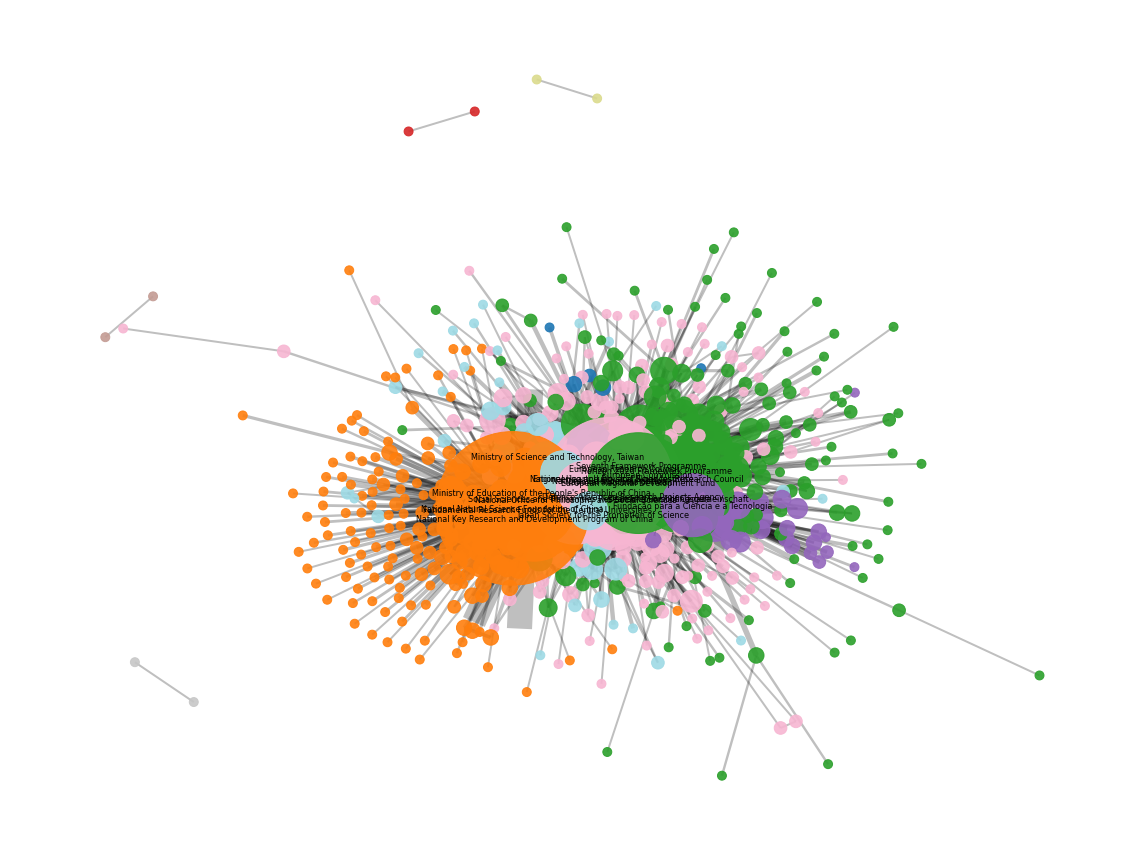

In [25]:
# ============================================================
# Figure 3.8
# Whole-period LIS Co-funding Network, 2014–2024
#
# Node size = degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------
# Filter graph for visualization
#
# Keep edges with weight >= 2
# This improves readability.
# ------------------------------------------------------------

min_edge_weight = 5

edges_to_keep = [
    (u, v)
    for u, v, d in G.edges(data=True)
    if d["weight"] >= min_edge_weight
]

G_vis = G.edge_subgraph(edges_to_keep).copy()

print("Visualization network")
print("---------------------")
print("Nodes:", G_vis.number_of_nodes())
print("Edges:", G_vis.number_of_edges())

# ------------------------------------------------------------
# Louvain communities for visualization graph
# ------------------------------------------------------------

partition_vis = community_louvain.best_partition(
    G_vis,
    weight="weight",
    random_state=42
)

# ------------------------------------------------------------
# Node size = degree
# ------------------------------------------------------------

degree_vis = dict(G_vis.degree())

node_sizes = [
    degree_vis[n] * 80
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Node color = community
# ------------------------------------------------------------

node_colors = [
    partition_vis[n]
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Edge width = edge weight
# ------------------------------------------------------------

edge_widths = [
    G_vis[u][v]["weight"] * 0.4
    for u, v in G_vis.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_vis,
    weight="weight",
    seed=42,
    k=0.25
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_vis,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_vis,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# ------------------------------------------------------------
# Label only top funders by degree
# ------------------------------------------------------------

top_label_nodes = (
    pd.Series(degree_vis)
    .sort_values(ascending=False)
    .head(20)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_vis,
    pos,
    labels=labels,
    font_size=8
)

# plt.title(
#     "Figure 3.8. Whole-period LIS Co-funding Network, 2014–2024"
# )

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

Top funders network
-------------------
Nodes: 100
Edges: 3198


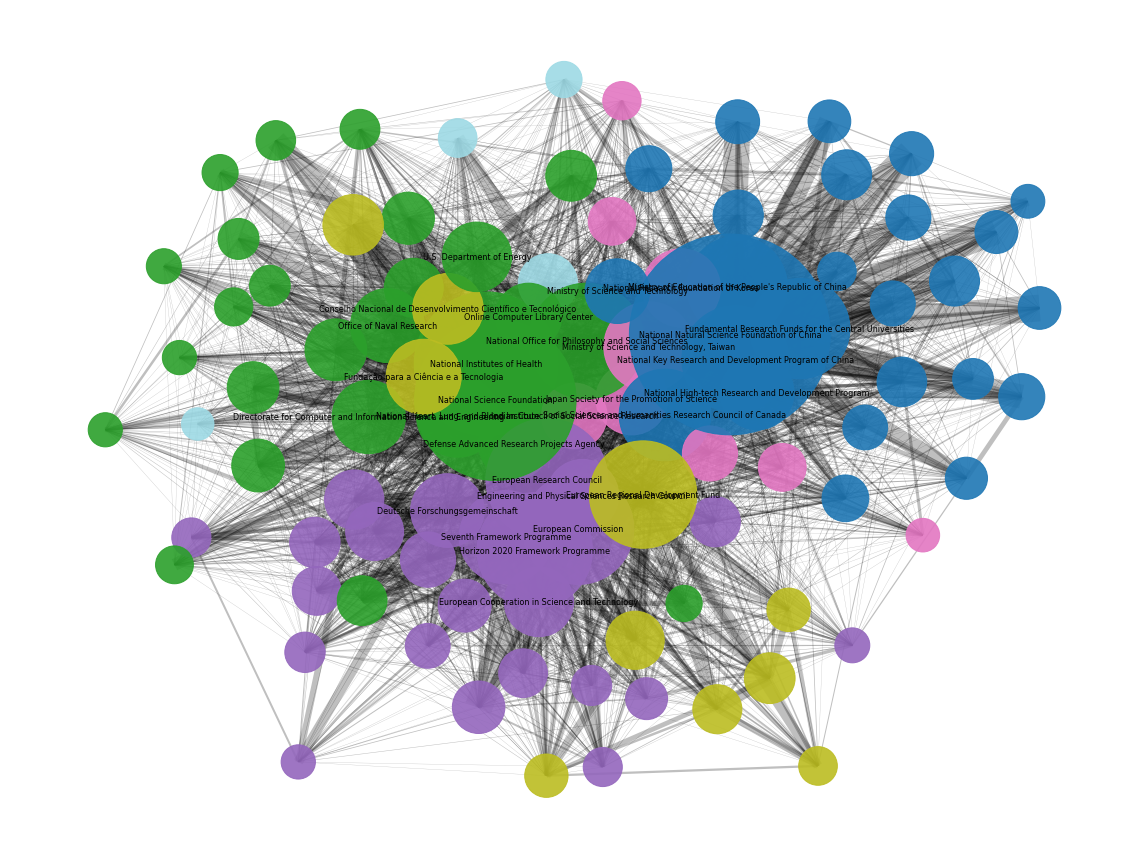

In [28]:
# ============================================================
# Figure 3.8
# Top 100 Funders Co-funding Network
#
# Node size = weighted degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# ------------------------------------------------------------
# Select top 100 funders by weighted degree
# ------------------------------------------------------------

top_n = 100

top_funders = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(top_n)
    ["Funder"]
    .tolist()
)

G_top = G.subgraph(top_funders).copy()

print("Top funders network")
print("-------------------")
print("Nodes:", G_top.number_of_nodes())
print("Edges:", G_top.number_of_edges())

# ------------------------------------------------------------
# Node attributes
# ------------------------------------------------------------

weighted_degree_top = dict(
    G_top.degree(weight="weight")
)

degree_top = dict(
    G_top.degree()
)

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

node_sizes = [
    weighted_degree_top[n] * 8
    for n in G_top.nodes()
]

node_colors = [
    community_map.get(n, -1)
    for n in G_top.nodes()
]

edge_widths = [
    max(0.3, G_top[u][v]["weight"] * 0.25)
    for u, v in G_top.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_top,
    weight="weight",
    seed=42,
    k=0.45,
    iterations=100
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_top,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_top,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# Label top 30 funders by weighted degree
top_label_nodes = (
    pd.Series(weighted_degree_top)
    .sort_values(ascending=False)
    .head(30)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_top,
    pos,
    labels=labels,
    font_size=8
)

# plt.title(
#     "Figure 3.8. Top 100 Funders Co-funding Network, 2014–2024"
# )

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

Community network
-----------------
Communities: 17
Between-community edges: 33
Major community network
-----------------------
Communities: 7
Edges: 21


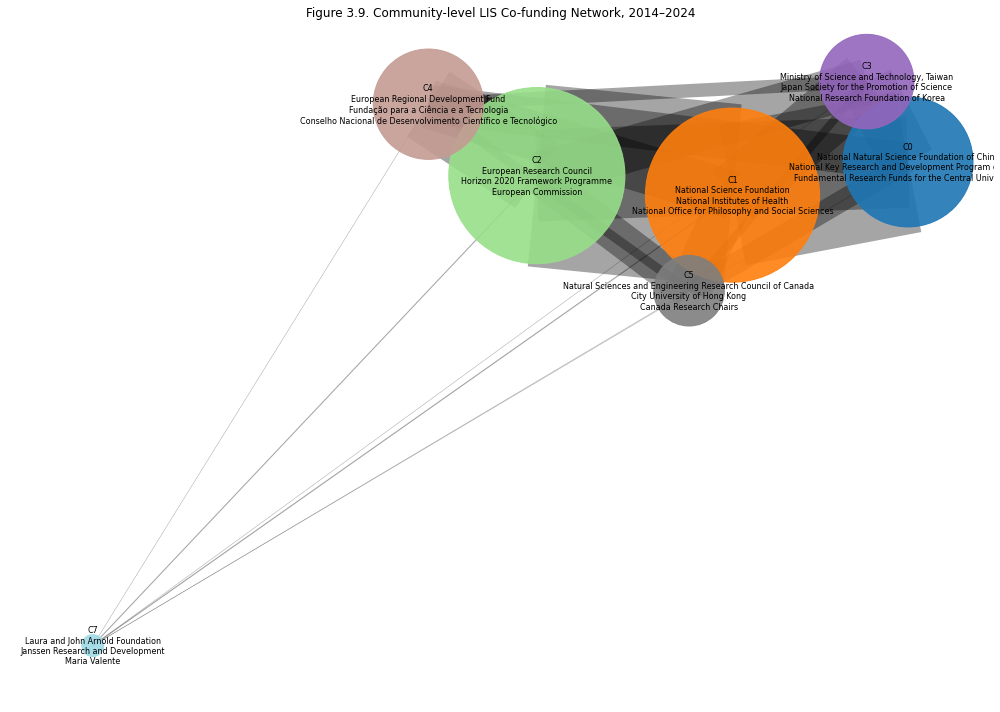

In [27]:
# ============================================================
# Figure 3.9
# Community-level Co-funding Network
#
# Node = Louvain community
# Node size = number of funders in community
# Edge width = total co-funding weight between communities
# ============================================================

import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

# ------------------------------------------------------------
# Community assignment
# ------------------------------------------------------------

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

# ------------------------------------------------------------
# Create community-level graph
# ------------------------------------------------------------

G_comm = nx.Graph()

# Add community nodes
community_sizes = (
    centrality_df
    .groupby("Community")
    ["Funder"]
    .count()
    .to_dict()
)

for comm, size in community_sizes.items():
    G_comm.add_node(
        comm,
        size=size
    )

# Add community-level edges
for u, v, data in G.edges(data=True):

    comm_u = community_map.get(u)
    comm_v = community_map.get(v)

    if comm_u is None or comm_v is None:
        continue

    # Skip within-community edges for between-community network
    if comm_u == comm_v:
        continue

    weight = data["weight"]

    if G_comm.has_edge(comm_u, comm_v):
        G_comm[comm_u][comm_v]["weight"] += weight
    else:
        G_comm.add_edge(
            comm_u,
            comm_v,
            weight=weight
        )

print("Community network")
print("-----------------")
print("Communities:", G_comm.number_of_nodes())
print("Between-community edges:", G_comm.number_of_edges())

# ------------------------------------------------------------
# Optional:
# Keep only major communities
# ------------------------------------------------------------

min_community_size = 10

major_communities = [
    comm
    for comm, size in community_sizes.items()
    if size >= min_community_size
]

G_comm_vis = G_comm.subgraph(major_communities).copy()

print("Major community network")
print("-----------------------")
print("Communities:", G_comm_vis.number_of_nodes())
print("Edges:", G_comm_vis.number_of_edges())

# ------------------------------------------------------------
# Node size and edge width
# ------------------------------------------------------------

node_sizes = [
    G_comm_vis.nodes[n]["size"] * 30
    for n in G_comm_vis.nodes()
]

edge_widths = [
    max(0.5, G_comm_vis[u][v]["weight"] * 0.02)
    for u, v in G_comm_vis.edges()
]

# ------------------------------------------------------------
# Labels:
# Community number + top funders
# ------------------------------------------------------------

community_top_funders = {}

for comm in G_comm_vis.nodes():

    top_funders = (
        centrality_df[
            centrality_df["Community"] == comm
        ]
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(3)
        .tolist()
    )

    community_top_funders[comm] = (
        f"C{comm}\n" + "\n".join(top_funders)
    )

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_comm_vis,
    weight="weight",
    seed=42,
    k=1.2,
    iterations=100
)

# ------------------------------------------------------------
# Draw community network
# ------------------------------------------------------------

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    G_comm_vis,
    pos,
    width=edge_widths,
    alpha=0.35
)

nx.draw_networkx_nodes(
    G_comm_vis,
    pos,
    node_size=node_sizes,
    node_color=list(G_comm_vis.nodes()),
    cmap=plt.cm.tab20,
    alpha=0.9
)

nx.draw_networkx_labels(
    G_comm_vis,
    pos,
    labels=community_top_funders,
    font_size=8
)

plt.title(
    "Figure 3.9. Community-level LIS Co-funding Network, 2014–2024"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()